
## Modelagem: Filtragem Colaborativa Baseada em Itens com KNN
 

---

### Contexto

O Portal Aventura ainda não possui um mecanismo estruturado de recomendação de espetáculos. Na prática, isso limita a descoberta de novas experiências: o usuário acessa um espetáculo específico, mas não recebe sugestões relacionadas ao seu comportamento ou a perfis semelhantes.

Este notebook implementa a etapa de modelagem utilizando o dataset balanceado preparado na etapa anterior. O objetivo é construir um modelo de filtragem colaborativa baseada em itens capaz de, dado um espetáculo de referência, identificar e recomendar outros espetáculos com padrões de avaliação similares entre os usuários.

Ao final do pipeline, são gerados os artefatos principais abaixo:

| Arquivo | Finalidade |
|---|---|
| `../modelos/modelo_knn.pkl` | Alias do modelo final com `k=20`, pronto para inferência |
| `../modelos/modelo_knn_k15.pkl` | Modelo KNN treinado para comparação com `k=15` |
| `../modelos/modelo_knn_k20.pkl` | Modelo KNN treinado para comparação e uso final com `k=20` |
| `../modelos/matriz_esparsa.pkl` | Matriz CSR utilizada no treinamento |
| `../modelos/mapeamentos_itens.pkl` | Dicionários de índice para decodificação dos resultados |
---

### Estrutura do Notebook

| Secao | Descricao |
|---|---|
| 1. Configuracao do Ambiente | Imports e configuracoes globais |
| 2. Conexão com a Base da Sprint 1 | Análise crítica do dataset gerado na etapa anterior |
| 3. Carregamento dos Dados | Leitura do dataset balanceado |
| 4. Análise Exploratória | Visão geral do dataset de modelagem |
| 5. Construção da Matriz Item-Usuário | Pivot table, esparsidade e matriz CSR |
| 6. Fundamentacao Teorica | Item-Based vs User-Based e Similaridade Cosseno |
| 7. Modelagem com KNN | Treinamento com NearestNeighbors |
| 8. Função de Recomendação | Implementação, inferência e exemplos práticos |
| 9. Avaliação do Modelo | RMSE e MAE |
| 10. Preparacao para Comparacao com SVD | Estrutura comparativa |
| 11. Exportação do Modelo | Serialização com joblib |
| 12. Conclusão | Descobertas, métricas e próximos passos |

---
## 1. Configuracao do Ambiente

Antes de iniciar a modelagem, importamos todas as bibliotecas necessarias. A organizacao dos imports por categoria facilita a manutencao e leitura do codigo.

In [50]:
# Bibliotecas principais
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

# Modelo e avaliação
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

# Serialização
import joblib
import os
from pathlib import Path

# Estilo de visualização
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Caminhos do projeto independentes do diret?rio em que o notebook ? executado.
CWD = Path.cwd().resolve()
if CWD.parent.name == 'src':
    PROJECT_ROOT = CWD.parents[1]
elif (CWD / 'src').exists():
    PROJECT_ROOT = CWD
else:
    PROJECT_ROOT = (CWD / '../..').resolve()

IMG_DIR = PROJECT_ROOT / 'documentos' / 'img'
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Remove imagens antigas que vers?es anteriores do notebook geravam em src/models.
for legacy_png in ['eda_modelagem.png', 'mapa_similaridade_knn.png', 'avaliacao_knn.png']:
    legacy_path = PROJECT_ROOT / 'src' / 'aad' / legacy_png
    if legacy_path.exists():
        legacy_path.unlink()

print('Ambiente configurado')
print(f'Pandas  : {pd.__version__}')
print(f'NumPy   : {np.__version__}')
print(f'Sklearn : {__import__("sklearn").__version__}')


Ambiente configurado
Pandas  : 2.3.3
NumPy   : 2.4.1
Sklearn : 1.8.0


---
## 2. Conexão com a Base da Sprint 1

Esta seção estabelece a conexão crítica entre o pipeline de preparação de dados da etapa anterior e o modelo construído aqui. O objetivo não e reprocessar os dados, mas sim analisar como as decisoes metodologicas da Sprint 1 impactam diretamente a qualidade e as limitacoes deste modelo.

### 2.1 O que veio da Sprint 1

A base original continha registros transacionais de compras de ingressos, sem nenhuma avaliacao explicita dos usuarios. As principais transformacoes realizadas na Sprint 1 foram:

| Decisao | Descricao | Impacto neste modelo |
|---|---|---|
| Feedback implícito | Rating derivado de recorrencia (60%), valor do ingresso (25%) e antecedencia da compra (15%) | Os ratings que alimentam o KNN não sao percepcoes subjetivas do usuario, mas proxies comportamentais |
| Remoção do outlier (ID 68564) | Usuário com 79.505 registros foi removido | Preveniu que um único perfil distorcesse toda a matriz de similaridade |
| Filtro de cold-start | Usuários com menos de 3 interações e itens com menos de 10 foram removidos | Garante que todos os vetores na matriz tenham densidade mínima para cálculo de similaridade |
| Balanceamento por quintis | Ratings distribuidos uniformemente de 1 a 5 por quantil do score continuo | A distribuição balanceada evita que a similaridade cosseno seja dominada por uma unica faixa de rating |
| Codificacao de IDs | `id_user` e `nome_evento` convertidos em indices inteiros continuos | Compatibilidade direta com a matriz numerica exigida pelo NearestNeighbors |

### 2.2 Lições aprendidas e impacto nos resultados

A substituição de ratings sintéticos por feedback implícito foi a decisão mais relevante da Sprint 1 para a qualidade deste modelo. Ratings gerados artificialmente com distribuição probabilística introduziriam ruído sistemático na matriz de similaridade, dois espetaculos pareceriam similares não porque usuarios com perfis parecidos os consumiram, mas por coincidencia da distribuição aleatória dos números.

Com o score implícito, a similaridade cosseno calculada nesta etapa reflete padrões reais de comportamento: espetaculos que atraem o mesmo perfil de usuario engajado (que volta, paga mais ou compra com antecedencia) tendem a ter vetores mais próximos no espaço matricial.

### 2.3 Limitações herdadas

Três limitações relevantes da Sprint 1 se propagam para este modelo:

1. **Esparsidade elevada (98,62%)**: mesmo após os filtros de cold-start, a grande maioria dos pares usuario-item não possui interacao. Isso reduz a cobertura das predicoes do KNN — pares sem vizinhos avaliados em comum não geram estimativa de rating.

2. **Ausência de atributos de conteúdo**: o modelo usa apenas ratings. Espetáculos da mesma categoria ou do mesmo tipo de produção poderiam ser penalizados por esparsidade, mesmo sendo objetivamente similares. A integração dos metadados de `itens_metadata.csv` e um passo natural para expandir o modelo.

3. **Hipoteses de ponderacao não validadas empiricamente**: os pesos 60/25/15 do score implícito foram definidos com criterio metodologico, mas não testados contra uma métrica de satisfacao real do usuario. Ajustes nesses pesos podem alterar a ordenacao dos ratings e, consequentemente, os resultados do modelo.

---
## 3. Carregamento dos Dados

Nesta etapa, o dataset balanceado gerado na Sprint 1 e carregado a partir do arquivo versionado em `src/dataset/recomendacao_balanceado.csv`. Tambem sao carregados os metadados dos itens para permitir a interpretacao dos resultados.

As colunas obrigatorias para a modelagem sao:

| Coluna | Tipo | Descricao |
|---|---|---|
| `user_id` | int | Indice numerico do usuario (codificado na Sprint 1) |
| `item_id` | int | Indice numerico do espetaculo (codificado na Sprint 1) |
| `rating` | float | Rating de 1 a 5 derivado do score implícito por quintis |

In [51]:
# Carregar dados preparados no tratamento
DATASET_PATH = '../dataset/recomendacao_balanceado.csv'
ITEM_META_PATH = '../dataset/itens_metadata.csv'

df_raw = pd.read_csv(DATASET_PATH)
item_meta = pd.read_csv(ITEM_META_PATH)

# Validar colunas mínimas para a modelagem
colunas_necessarias = ['user_id', 'item_id', 'rating']
assert all(col in df_raw.columns for col in colunas_necessarias),     f'Dataset precisa conter: {colunas_necessarias}'

df = df_raw[colunas_necessarias].copy()

print('Datasets carregados')
print(f'Registros de modelagem : {len(df):,}')
print(f'Itens com metadados    : {len(item_meta):,}')
df.head(10)


Datasets carregados
Registros de modelagem : 40,848
Itens com metadados    : 343


,user_id,item_id,rating
0,0,0,2.0
1,1,1,4.0
2,2,2,1.0
3,3,3,1.0
4,4,4,1.0
5,5,5,3.0
6,6,6,1.0
7,7,7,3.0
8,8,8,5.0
9,9,9,2.0


---
## 4. Checagem Exploratória do Dataset de Modelagem

A análise exploratória completa foi realizada no notebook `tratamento-dados.ipynb`. Nesta etapa, fazemos apenas uma checagem direcionada à modelagem: volume de usuários e itens, distribuição dos ratings, densidade da matriz e quantidade de interações por usuário e espetáculo. Esses pontos são suficientes para validar se o dataset final está adequado ao KNN e para interpretar as limitações do modelo.

In [52]:
# Checagem mínima necessária antes da modelagem
n_usuarios = df['user_id'].nunique()
n_itens    = df['item_id'].nunique()
n_ratings  = len(df)
densidade  = n_ratings / (n_usuarios * n_itens) * 100

print('=== Informações Gerais do Dataset de Modelagem ===')
print(f'   Usuários únicos        : {n_usuarios:>10,}')
print(f'   Espetáculos únicos     : {n_itens:>10,}')
print(f'   Total de interações    : {n_ratings:>10,}')
print(f'   Densidade da matriz    : {densidade:>9.4f}%')
print(f'   Rating medio           : {df["rating"].mean():>10.2f}')
print(f'   Rating minimo          : {df["rating"].min():>10.0f}')
print(f'   Rating maximo          : {df["rating"].max():>10.0f}')

print('\nValores nulos por coluna:')
print(df.isnull().sum().to_string())

print('\nInterações por usuario:')
display(df.groupby('user_id').size().describe().rename('interações').to_frame())

print('\nInterações por espetaculo:')
display(df.groupby('item_id').size().describe().rename('interações').to_frame())

=== Informações Gerais do Dataset de Modelagem ===
   Usuários únicos        :      8,648
   Espetáculos únicos     :        343
   Total de interações    :     40,848
   Densidade da matriz    :    1.3771%
   Rating medio           :       3.00
   Rating minimo          :          1
   Rating maximo          :          5

Valores nulos por coluna:
user_id    0
item_id    0
rating     0

Interações por usuario:


,interações
count,8648.000000
mean,4.723404
std,3.310856
min,1.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,69.000000



Interações por espetaculo:


,interações
count,343.000000
mean,119.090379
std,237.238463
min,10.000000
25%,21.000000
50%,46.000000
75%,100.500000
max,2176.000000


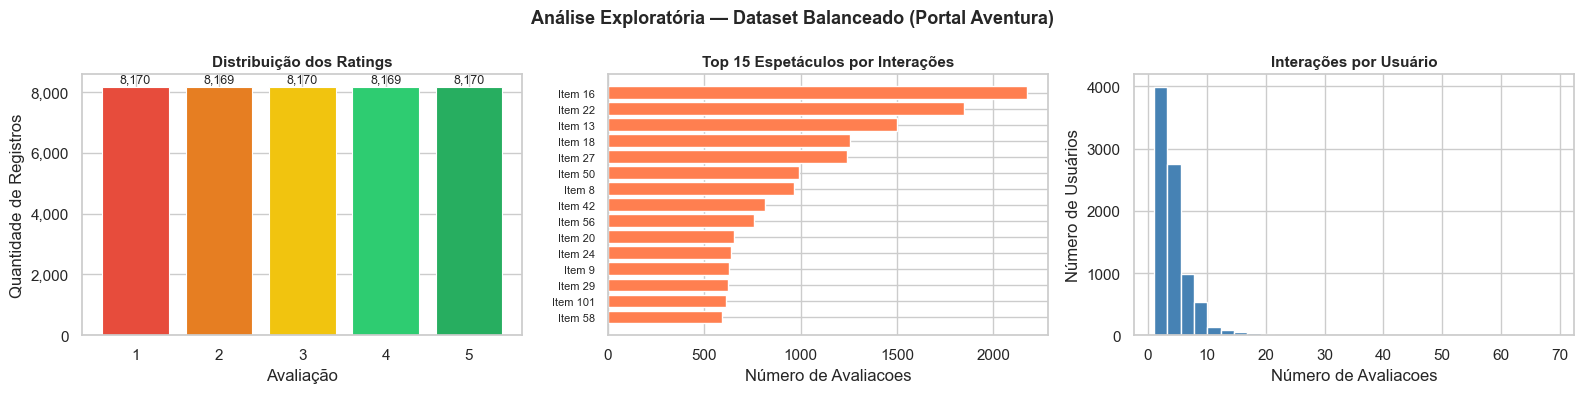

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Análise Exploratória — Dataset Balanceado (Portal Aventura)',
             fontsize=13, fontweight='bold')

colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']

# Distribuição dos ratings
rating_counts = df['rating'].value_counts().sort_index()
bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_title('Distribuição dos Ratings', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Avaliação')
axes[0].set_ylabel('Quantidade de Registros')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}', ha='center', va='bottom', fontsize=9)

# Top 15 espetáculos mais avaliados
top_itens = df['item_id'].value_counts().head(15)
axes[1].barh(range(len(top_itens)), top_itens.values[::-1],
             color='coral', edgecolor='white')
axes[1].set_yticks(range(len(top_itens)))
axes[1].set_yticklabels([f'Item {i}' for i in top_itens.index[::-1]], fontsize=8)
axes[1].set_title('Top 15 Espetáculos por Interações', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Número de Avaliacoes')

# Distribuição de avaliacoes por usuário
avals_por_usuário = df.groupby('user_id')['rating'].count()
axes[2].hist(avals_por_usuário, bins=30, color='steelblue', edgecolor='white')
axes[2].set_title('Interações por Usuário', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Número de Avaliacoes')
axes[2].set_ylabel('Número de Usuários')

plt.tight_layout()
plt.savefig(IMG_DIR / 'eda_modelagem.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 5. Construcao da Matriz Item-Usuário

### Por que precisamos de uma matriz?

O KNN opera em um espaço vetorial: cada espetaculo e representado como um vetor cujas dimensões correspondem as avaliacoes dos usuarios. Para calcular a similaridade entre dois espetaculos, e preciso que ambos existam no mesmo espaço vetorial.

A Pivot Table transforma o formato longo `(user_id, item_id, rating)` em uma matriz estruturada:

| | user_0 | user_1 | user_2 | ... |
|---|---|---|---|---|
| **item_0** | 4.0 | NaN | 3.0 | ... |
| **item_1** | NaN | 5.0 | NaN | ... |
| **item_2** | 2.0 | 3.0 | NaN | ... |

- **Linhas** = Itens (espetaculos) — posicao no espaço vetorial
- **Colunas** = Usuários — dimensões do vetor
- **NaN** = Usuário não avaliou o item (celula vazia — gera esparsidade)

Os itens ficam nas linhas porque realizamos filtragem baseada em itens (Item-Based CF). O modelo compara vetores de itens, não de usuarios.

In [54]:
# Itens ficam nas linhas porque o modelo é item-based.
matriz_item_usuario = df.pivot_table(
    index='item_id',
    columns='user_id',
    values='rating',
    aggfunc='mean'
)

print('=== Matriz Item-Usuário ===')
print(f'   Dimensoes  : {matriz_item_usuario.shape[0]:,} itens x {matriz_item_usuario.shape[1]:,} usuarios')

total_celulas       = matriz_item_usuario.size
celulas_preenchidas = matriz_item_usuario.notna().sum().sum()
esparsidade         = (1 - celulas_preenchidas / total_celulas) * 100

print(f'\n   Celulas preenchidas : {celulas_preenchidas:>10,}')
print(f'   Celulas totais      : {total_celulas:>10,}')
print(f'   Esparsidade         : {esparsidade:>9.4f}%')

print('\nAmostra da Matriz (5x5):')
display(matriz_item_usuario.iloc[:5, :5])

=== Matriz Item-Usuário ===
   Dimensoes  : 343 itens x 8,648 usuarios

   Celulas preenchidas :     40,848
   Celulas totais      :  2,966,264
   Esparsidade         :   98.6229%

Amostra da Matriz (5x5):


user_id,0,1,2,3,4
item_id,,,,,
0,2.0,NaN,NaN,NaN,NaN
1,NaN,4.0,NaN,NaN,NaN
2,NaN,NaN,1.0,NaN,NaN
3,NaN,NaN,NaN,1.0,NaN
4,NaN,NaN,NaN,NaN,1.0


In [55]:
# Zero representa ausência de interação na matriz de similaridade.
matriz_preenchida = matriz_item_usuario.fillna(0)

matriz_esparsa = csr_matrix(matriz_preenchida.values)

# Mapeamentos necessários para converter índices da matriz em item_ids.
item_ids    = list(matriz_item_usuario.index)
item_to_idx = {item: idx for idx, item in enumerate(item_ids)}   # item_id -> indice
idx_to_item = {idx: item for item, idx in item_to_idx.items()}   # indice -> item_id

print('=== Matriz Esparsa Criada ===')
print(f'   Tipo           : {type(matriz_esparsa).__name__}')
print(f'   Shape          : {matriz_esparsa.shape}')
print(f'   Itens mapeados : {len(item_ids):,}')

=== Matriz Esparsa Criada ===
   Tipo           : csr_matrix
   Shape          : (343, 8648)
   Itens mapeados : 343


---
## 6. Fundamentacao Teorica

### 6.1 Por que Item-Based em vez de User-Based?

A filtragem colaborativa pode ser orientada a usuarios (encontrar usuarios similares e recomendar o que eles avaliaram positivamente) ou a itens (encontrar itens similares ao que o usuario ja avaliou). Para o contexto do Portal Aventura, a abordagem Item-Based e a mais adequada:

| Criterio | User-Based | Item-Based |
|---|---|---|
| Escalabilidade | Cresce com o número de usuarios | Estável — o catálogo de espetaculos e fixo por temporada |
| Estabilidade | Perfis de usuarios mudam com o tempo | Padroes de avaliacao por espetaculo sao estaveis após a temporada |
| Esparsidade | Sensivel — poucos usuarios em comum entre pares | Mais robusto a matrizes com alta esparsidade |
| Interpretabilidade | Moderada | Alta — quem gostou de A tambem gostou de B |
| Novos usuarios | Dificil — cold start severo | Recomenda com base no item acessado, sem historico do usuario |

No Portal Aventura, o catálogo de espetaculos e fixo após o encerramento de cada temporada, enquanto novos usuarios chegam continuamente. A abordagem Item-Based e, portanto, a escolha mais escalável e estavel para esse contexto.

---

### 6.2 A Matematica da Similaridade por Cosseno

A similaridade por cosseno mede o ângulo entre dois vetores no espaço multidimensional, sendo independente da magnitude (escala das avaliacoes):

$$\text{sim}(A, B) = \cos(\theta) = \frac{\vec{A} \cdot \vec{B}}{\|\vec{A}\| \cdot \|\vec{B}\|}$$

Onde:
- $\vec{A} \cdot \vec{B} = \sum_{u \in U} r_{u,A} \cdot r_{u,B}$ — produto escalar dos ratings
- $\|\vec{A}\| = \sqrt{\sum_{u \in U} r_{u,A}^2}$ — norma euclidiana do vetor A
- Resultado varia de **0** (sem similaridade) a **1** (vetores identicos)

**Exemplo numerico com espetaculos do Portal Aventura:**

| Usuário | Espetaculo A | Espetaculo B |
|---|---|---|
| user_1 | 5 | 4 |
| user_2 | 4 | 5 |
| user_3 | 0 | 0 |
| user_4 | 3 | 3 |

- Produto escalar: (5x4) + (4x5) + (0x0) + (3x3) = 20 + 20 + 0 + 9 = 49
- Norma A: raiz(25 + 16 + 0 + 9) = raiz(50) ≈ 7,07
- Norma B: raiz(16 + 25 + 0 + 9) = raiz(50) ≈ 7,07
- Similaridade: 49 / (7,07 x 7,07) ≈ **0,98** — espetaculos muito similares

O scikit-learn usa `metric='cosine'` que calcula a distância cosseno = 1 - similaridade. Portanto, menor distância equivale a maior similaridade.

---

### 6.3 O Algoritmo KNN Aplicado ao Portal Aventura

O processo de recomendação segue os seguintes passos:

1. Um usuario acessa a pagina do espetaculo X no portal
2. O vetor do espetaculo X e recuperado da matriz Item-Usuário
3. O KNN calcula a distância cosseno entre X e todos os outros espetaculos
4. Os `k` espetaculos com menor distância (maior similaridade) sao retornados
5. O portal exibe esses espetaculos na secao de recomendacoes da pagina

---
## 7. Modelagem com KNN

O `NearestNeighbors` do scikit-learn implementa a busca pelos vizinhos mais próximos. Optamos por `algorithm='brute'` (busca exaustiva) por ser o único algoritmo do scikit-learn compatível com a métrica cosseno em matrizes esparsas. Para o tamanho do catálogo do Portal Aventura, o custo computacional e aceitável.

In [56]:
# Hiperparâmetros do KNN item-based
N_VIZINHOS = 20        # número de vizinhos a buscar (inclui o próprio item)
METRICA    = 'cosine'  # distância cosseno = 1 - similaridade_cosseno
ALGORITMO  = 'brute'   # busca exaustiva: único compatível com cosseno + CSR

modelo_knn = NearestNeighbors(
    n_neighbors=N_VIZINHOS,
    metric=METRICA,
    algorithm=ALGORITMO,
    n_jobs=-1
)

modelo_knn.fit(matriz_esparsa)

print('=== Modelo KNN Treinado ===')
print(f'   Métrica    : {modelo_knn.metric}')
print(f'   Algoritmo  : {modelo_knn.algorithm}')
print(f'   N vizinhos : {modelo_knn.n_neighbors}')
print(f'   Shape      : {matriz_esparsa.shape[0]:,} itens x {matriz_esparsa.shape[1]:,} usuarios')

=== Modelo KNN Treinado ===
   Métrica    : cosine
   Algoritmo  : brute
   N vizinhos : 20
   Shape      : 343 itens x 8,648 usuarios


---
## 8. Função de Recomendação e Inferencia

A funcao abaixo encapsula toda a logica de recomendação e constitui a interface de inferência do modelo. Dado um espetaculo de referencia (`item_id`), ela retorna os `n` espetaculos mais similares, ordenados pela similaridade cosseno decrescente, com os nomes dos espetaculos recuperados dos metadados.

**Fluxo interno:**
1. Valida se o `item_id` existe no catálogo
2. Recupera o vetor do espetaculo na matriz esparsa
3. Consulta o KNN pelos `n+1` vizinhos (o +1 e necessário pois o próprio item aparece como vizinho de distância zero)
4. Converte distâncias em scores de similaridade: `sim = 1 - dist`
5. Faz join com metadados para exibir o nome do espetaculo
6. Retorna DataFrame ordenado por similaridade decrescente

In [57]:
def recomendar_espetaculos(item_id, n_recomendacoes=10, verbose=True):
    """
    Recomenda espetaculos similares a um espetaculo-alvo usando KNN Item-Based.

    Esta funcao utiliza o modelo treinado (modelo_knn) e a matriz esparsa
    (matriz_esparsa) que devem estar carregados no ambiente. Para uso com
    o modelo exportado, carregue os artefatos com joblib antes de chamar
    esta funcao (ver Secao 11).

    Parametros
    ----------
    item_id : int
        ID numerico do espetaculo de referencia (indice codificado na Sprint 1).
    n_recomendacoes : int
        Numero de recomendacoes a retornar. Padrao: 10.
    verbose : bool
        Se True, exibe cabecalho com o espetaculo de referencia. Padrao: True.

    Retorna
    -------
    pd.DataFrame
        Colunas: item_id_recomendado | nome_evento | distância_cosseno | similaridade
        Index  : rank (1 = mais similar)

    Raises
    ------
    ValueError
        Se o item_id não existir no catálogo indexado.
    """

    if item_id not in item_to_idx:
        raise ValueError(
            f"item_id '{item_id}' não encontrado no catálogo.\n"
            f"Utilize um dos {len(item_ids):,} itens disponiveis."
        )

    idx_alvo   = item_to_idx[item_id]
    vetor_alvo = matriz_esparsa[idx_alvo]     # vetor linha CSR

    # Busca n+1 vizinhos porque o próprio item aparece com distância zero.
    distâncias, indices = modelo_knn.kneighbors(
        vetor_alvo,
        n_neighbors=n_recomendacoes + 1
    )

    distâncias = distâncias.flatten()
    indices    = indices.flatten()

    mascara    = indices != idx_alvo
    distâncias = distâncias[mascara][:n_recomendacoes]
    indices    = indices[mascara][:n_recomendacoes]

    similaridades = 1 - distâncias

    recomendacoes = pd.DataFrame({
        'item_id_recomendado' : [idx_to_item[i] for i in indices],
        'distância_cosseno'   : distâncias,
        'similaridade'        : similaridades
    })

    recomendacoes = recomendacoes.merge(
        item_meta[['item_id', 'nome_evento', 'categoria']],
        left_on='item_id_recomendado',
        right_on='item_id',
        how='left'
    ).drop(columns=['item_id'])

    recomendacoes = recomendacoes.sort_values('similaridade', ascending=False).reset_index(drop=True)
    recomendacoes.index      = range(1, len(recomendacoes) + 1)
    recomendacoes.index.name = 'rank'

    if verbose:
        nome_ref = item_meta.loc[item_meta['item_id'] == item_id, 'nome_evento']
        nome_str = nome_ref.values[0] if len(nome_ref) > 0 else f'ID {item_id}'
        print(f'=== Recomendações para: {nome_str} (ID {item_id}) ===')
        print(f'   Top {n_recomendacoes} espetaculos mais similares:')

    return recomendacoes

print('Função de recomendação definida com sucesso')


Função de recomendação definida com sucesso


In [58]:
# Exemplo 1: espetáculo mais avaliado do catálogo
item_exemplo_1 = df['item_id'].value_counts().index[0]
rec1 = recomendar_espetaculos(item_exemplo_1, n_recomendacoes=10)
display(rec1)


=== Recomendações para: A NOVIÇA REBELDE (ID 16) ===
   Top 10 espetaculos mais similares:


,item_id_recomendado,distância_cosseno,similaridade,nome_evento,categoria
rank,,,,,
1,22,0.600421,0.399579,MUSICAL HAIRSPRAY,Espetáculo Musical
2,13,0.775400,0.224600,NOSSA HISTÓRIA COM CHICO BUARQUE,Show Musical
3,8,0.798346,0.201654,"ELIS, A MUSICAL",Espetáculo Musical
4,18,0.810661,0.189339,PRIMA FACIE COM DÉBORA FALABELLA,Espetáculo Teatral
5,27,0.827264,0.172736,CLUBE DA ESQUINA - OS SONHOS NÃO ENVELHECEM,Show Musical
6,20,0.847407,0.152593,BIBI – UMA VIDA EM MUSICAL,Espetáculo Musical
7,69,0.853139,0.146861,BROADWAY NIGHT´S,Espetáculo Musical
8,12,0.859384,0.140616,HOMEM COM H,Espetáculo Musical
9,42,0.861357,0.138643,PORTÁTIL,Espetáculo Teatral


In [59]:
# Exemplo 2: segundo espetáculo mais avaliado
item_exemplo_2 = df['item_id'].value_counts().index[1]
rec2 = recomendar_espetaculos(item_exemplo_2, n_recomendacoes=10)
display(rec2)


=== Recomendações para: MUSICAL HAIRSPRAY (ID 22) ===
   Top 10 espetaculos mais similares:


,item_id_recomendado,distância_cosseno,similaridade,nome_evento,categoria
rank,,,,,
1,16,0.600421,0.399579,A NOVIÇA REBELDE,Espetáculo Musical
2,13,0.778187,0.221813,NOSSA HISTÓRIA COM CHICO BUARQUE,Show Musical
3,8,0.791860,0.208140,"ELIS, A MUSICAL",Espetáculo Musical
4,69,0.821456,0.178544,BROADWAY NIGHT´S,Espetáculo Musical
5,27,0.832482,0.167518,CLUBE DA ESQUINA - OS SONHOS NÃO ENVELHECEM,Show Musical
6,20,0.835252,0.164748,BIBI – UMA VIDA EM MUSICAL,Espetáculo Musical
7,9,0.844453,0.155547,"A COR PÚRPURA, O MUSICAL",Espetáculo Musical
8,12,0.854989,0.145011,HOMEM COM H,Espetáculo Musical
9,18,0.858395,0.141605,PRIMA FACIE COM DÉBORA FALABELLA,Espetáculo Teatral


In [60]:
# Exemplo 3: terceiro espetáculo mais avaliado
item_exemplo_3 = df['item_id'].value_counts().index[2]
rec3 = recomendar_espetaculos(item_exemplo_3, n_recomendacoes=10)
display(rec3)


=== Recomendações para: NOSSA HISTÓRIA COM CHICO BUARQUE (ID 13) ===
   Top 10 espetaculos mais similares:


,item_id_recomendado,distância_cosseno,similaridade,nome_evento,categoria
rank,,,,,
1,8,0.755205,0.244795,"ELIS, A MUSICAL",Espetáculo Musical
2,16,0.775400,0.224600,A NOVIÇA REBELDE,Espetáculo Musical
3,22,0.778187,0.221813,MUSICAL HAIRSPRAY,Espetáculo Musical
4,27,0.789191,0.210809,CLUBE DA ESQUINA - OS SONHOS NÃO ENVELHECEM,Show Musical
5,18,0.808634,0.191366,PRIMA FACIE COM DÉBORA FALABELLA,Espetáculo Teatral
6,50,0.820964,0.179036,MACACOS,Espetáculo Teatral
7,6,0.826934,0.173066,NOEL ROSA: COISA NOSSA,Show Musical
8,29,0.829151,0.170849,VIVA O POVO BRASILEIRO [DE NAÊ À DAFÉ],Show Musical
9,101,0.830203,0.169797,A ULTIMA SESSÃO DE FREUD COM ODILON WAGNER E M...,Espetáculo Teatral


### Leitura dos Exemplos de Inferência

Os exemplos de recomendação demonstram que a função de inferência retorna listas coerentes a partir de espetáculos de referência, com itens ordenados por similaridade cosseno e enriquecidos com nome e categoria. Como o modelo é puramente colaborativo, a proximidade entre espetáculos reflete padrões de cointeração entre usuários, e não semelhança textual ou curadoria manual de conteúdo.

Esse comportamento é adequado para um primeiro modelo interpretável do portal, mas também evidencia uma limitação: espetáculos novos ou pouco avaliados tendem a receber recomendações menos confiáveis até acumularem interações suficientes.


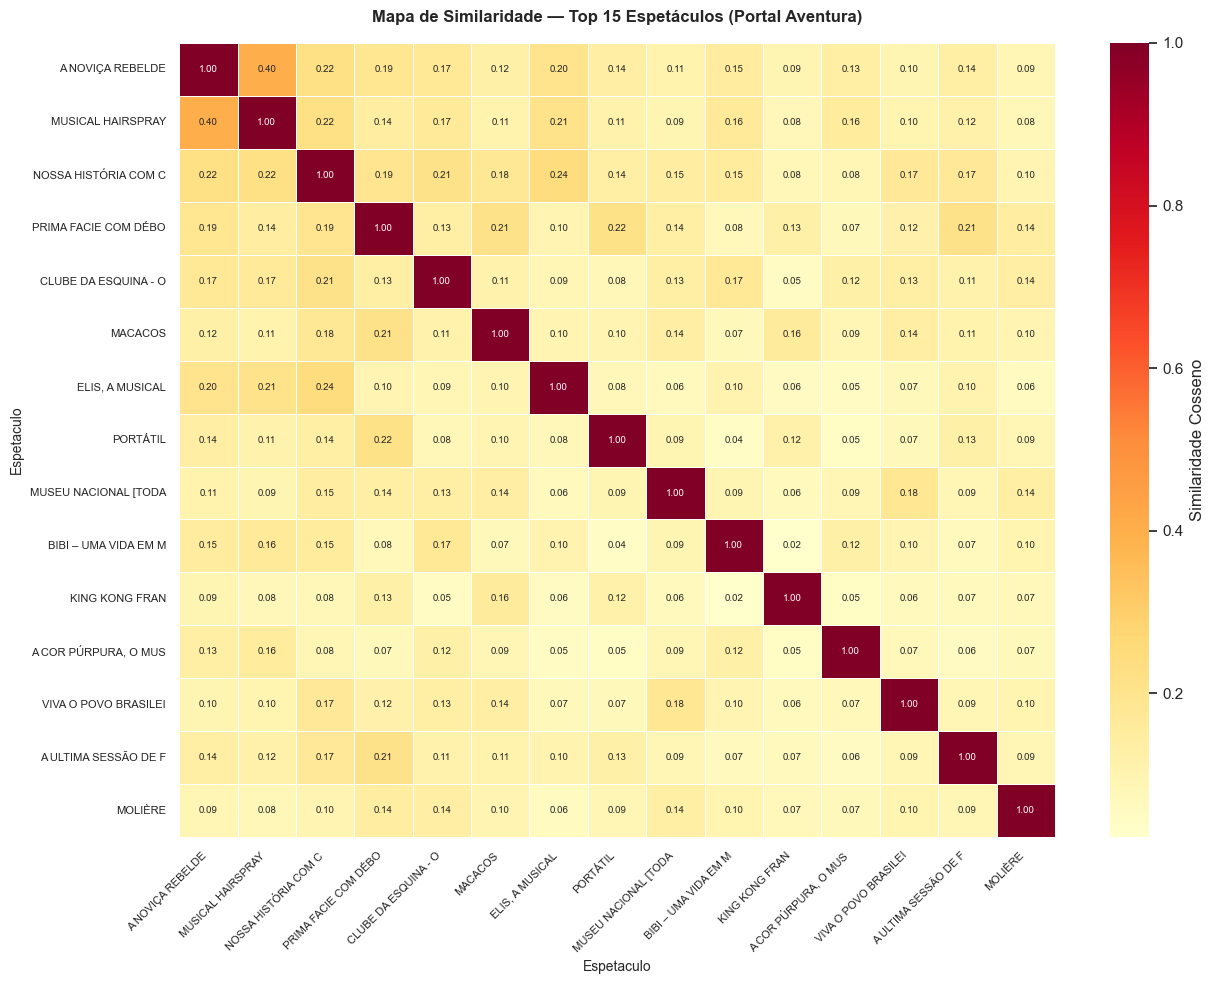

In [61]:
# Mapa de similaridade entre os Top 15 espetáculos mais avaliados
TOP_N_VISUAL = 15

top_itens_visual = df['item_id'].value_counts().head(TOP_N_VISUAL).index.tolist()
indices_top      = [item_to_idx[i] for i in top_itens_visual]
submatriz        = matriz_esparsa[indices_top]

# Cada célula da matriz item-item representa a similaridade cosseno entre dois espetáculos.
sim_matrix = cosine_similarity(submatriz)

# Recuperar nomes dos espetáculos para o eixo
nomes_top = []
for iid in top_itens_visual:
    nome = item_meta.loc[item_meta['item_id'] == iid, 'nome_evento']
    nomes_top.append(nome.values[0][:20] if len(nome) > 0 else f'ID {iid}')

sim_df = pd.DataFrame(sim_matrix, index=nomes_top, columns=nomes_top)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(sim_df, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Similaridade Cosseno'},
            annot_kws={'size': 7})
ax.set_title(
    f'Mapa de Similaridade — Top {TOP_N_VISUAL} Espetáculos (Portal Aventura)',
    fontsize=12, fontweight='bold', pad=15
)
ax.set_xlabel('Espetaculo', fontsize=10)
ax.set_ylabel('Espetaculo', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(IMG_DIR / 'mapa_similaridade_knn.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 9. Avaliação do Modelo: Erro, Cobertura e Ranking

### Como avaliar quantitativamente o KNN Item-Based?

O KNN não prevê ratings diretamente como um modelo de regressão. Para avaliação quantitativa, adotamos a seguinte estratégia:

1. Dividimos o dataset em treino (80%) e teste (20%)
2. Treinamos um KNN apenas com os dados de treino — sem acesso ao conjunto de teste
3. Para cada par `(user_id, item_id)` no teste, estimamos o rating usando a média ponderada pela similaridade dos `k` itens vizinhos que o usuário avaliou:

$$\hat{r}_{u,i} = \frac{\sum_{j \in N(i)} \text{sim}(i,j) \cdot r_{u,j}}{\sum_{j \in N(i)} |\text{sim}(i,j)|}$$

Onde $N(i)$ é o conjunto dos $k$ itens mais similares ao item $i$ que o usuário $u$ já avaliou.

Além do valor principal `k=20`, avaliamos também `k=15`. A comparação permite verificar se o aumento da vizinhança melhora a cobertura sem piorar excessivamente RMSE e MAE, justificando a escolha do hiperparâmetro usado no modelo final.

4. Calculamos **RMSE** e **MAE** entre os ratings reais e previstos:

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat{r}_i - r_i)^2} \qquad MAE = \frac{1}{n}\sum_{i=1}^{n}|\hat{r}_i - r_i|$$

**RMSE** penaliza erros grandes de forma quadrática, sendo sensível a outliers de predição. **MAE** representa o erro absoluto médio em unidades da escala original (1 a 5), sendo de interpretação mais direta. Ambas as métricas são adequadas para avaliar modelos de recomendação baseados em rating.

Além dessas métricas de erro, reportamos a **cobertura**: percentual de pares no conjunto de teste para os quais foi possível gerar uma predição. Pares sem vizinhos com avaliações em comum não geram predição e são excluídos do cálculo de RMSE/MAE.

Também incluímos uma métrica orientada a ranking, o **Hit Rate@10**. Para cada usuário avaliado, usamos um item observado no treino como referência e verificamos se algum item retido no teste aparece entre as 10 recomendações. Essa métrica aproxima melhor o uso real do sistema, pois avalia se a lista recomendada recupera itens que o usuário de fato consumiu.


In [62]:
# Avaliação holdout do KNN
print('=== Avaliação do Modelo KNN ===')
print('   Dividindo dados em treino (80%) e teste (20%)...')

df_treino, df_teste = train_test_split(
    df, test_size=0.2, random_state=42
)

print(f'   Treino : {len(df_treino):,} interações')
print(f'   Teste  : {len(df_teste):,} interações')

=== Avaliação do Modelo KNN ===
   Dividindo dados em treino (80%) e teste (20%)...
   Treino : 32,678 interações
   Teste  : 8,170 interações


In [63]:
# A matriz de avaliação usa apenas treino para evitar vazamento de dados.
matriz_treino = df_treino.pivot_table(
    index='item_id',
    columns='user_id',
    values='rating',
    aggfunc='mean'
).fillna(0)

matriz_treino_esparsa = csr_matrix(matriz_treino.values)

# Mapeamentos especificos para a matriz de treino
item_ids_treino = list(matriz_treino.index)
user_ids_treino = list(matriz_treino.columns)
item_to_idx_tr  = {item: idx for idx, item in enumerate(item_ids_treino)}
idx_to_item_tr  = {idx: item for item, idx in item_to_idx_tr.items()}
user_to_idx_tr  = {user: idx for idx, user in enumerate(user_ids_treino)}

K_AVALIACAO = N_VIZINHOS   # mesmo k usado no modelo final

knn_avaliacao = NearestNeighbors(
    n_neighbors=min(K_AVALIACAO + 1, len(item_ids_treino)),
    metric='cosine',
    algorithm='brute',
    n_jobs=-1
)
knn_avaliacao.fit(matriz_treino_esparsa)

print('KNN treinado com dados de treino para avaliacao')


KNN treinado com dados de treino para avaliacao


In [64]:
def prever_rating(user_id, item_id, k=K_AVALIACAO):
    """
    Estima o rating de um usuario para um espetaculo usando
    a media ponderada pela similaridade cosseno dos k vizinhos.
    Retorna NaN se não houver informacao suficiente.
    """
    if item_id not in item_to_idx_tr or user_id not in user_to_idx_tr:
        return np.nan

    idx_item = item_to_idx_tr[item_id]
    idx_user = user_to_idx_tr[user_id]

    dists, idxs = knn_avaliacao.kneighbors(
        matriz_treino_esparsa[idx_item], n_neighbors=k + 1
    )
    dists = dists.flatten()
    idxs  = idxs.flatten()

    mask  = idxs != idx_item
    dists = dists[mask][:k]
    idxs  = idxs[mask][:k]

    sims = 1 - dists

    ratings_viz = np.array([
        matriz_treino_esparsa[i, idx_user] for i in idxs
    ])

    # Só vizinhos já avaliados pelo usuário contribuem para a predição.
    avaliados = ratings_viz > 0
    if not avaliados.any():
        return np.nan

    soma_similaridades = sims[avaliados].sum()
    if soma_similaridades == 0:
        return np.nan

    return np.dot(sims[avaliados], ratings_viz[avaliados]) / soma_similaridades


In [65]:
warnings.filterwarnings(
    'ignore',
    message='`sklearn.utils.parallel.delayed`',
    category=UserWarning,
    module='sklearn.utils.parallel')
# Amostra de até 500 registros para manter a execução leve em ambiente acadêmico.
N_AMOSTRA        = min(500, len(df_teste))
df_teste_amostra = df_teste.sample(N_AMOSTRA, random_state=42)
K_COMPARACAO     = [15, 20]

print(f'Calculando predições para {N_AMOSTRA:,} registros do conjunto de teste...')

resultados_k = []
previsoes_por_k = {}

for k in K_COMPARACAO:
    y_real_k     = []
    y_previsto_k = []

    for _, row in df_teste_amostra.iterrows():
        pred = prever_rating(row['user_id'], row['item_id'], k=k)
        if not np.isnan(pred):
            y_real_k.append(row['rating'])
            y_previsto_k.append(pred)

    rmse_k      = np.sqrt(mean_squared_error(y_real_k, y_previsto_k)) if y_real_k else np.nan
    mae_k       = mean_absolute_error(y_real_k, y_previsto_k) if y_real_k else np.nan
    cobertura_k = len(y_real_k) / N_AMOSTRA * 100


    resultados_k.append({
        'k'                 : k,
        'RMSE'              : round(rmse_k, 4),
        'MAE'               : round(mae_k, 4),
        'Cobertura (%)'     : round(cobertura_k, 1),
        'Predições válidas' : len(y_real_k)
    })
    previsoes_por_k[k] = (y_real_k, y_previsto_k)

df_resultados_k = pd.DataFrame(resultados_k)
display(df_resultados_k.set_index('k'))

# Métricas oficiais do notebook: k=20, mesma configuração exportada para o modelo final.
y_real, y_previsto = previsoes_por_k[N_VIZINHOS]
rmse      = np.sqrt(mean_squared_error(y_real, y_previsto))
mae       = mean_absolute_error(y_real, y_previsto)
cobertura = len(y_real) / N_AMOSTRA * 100

print()
print('=== Resultados — KNN Item-Based (Portal Aventura) ===')
print(f'   k          : {N_VIZINHOS}')
print(f'   RMSE       : {rmse:.4f}')
print(f'   MAE        : {mae:.4f}')
print(f'   Cobertura  : {cobertura:.1f}% ({len(y_real)}/{N_AMOSTRA} predições válidas)')
print()
print('   Interpretação das métricas:')
print(f'     RMSE = {rmse:.4f} -> erro quadrático médio entre rating real e previsto (penaliza erros grandes)')
print(f'     MAE  = {mae:.4f} -> em média, a predição erra {mae:.2f} ponto(s) na escala de 1 a 5')
print(f'     Cobertura -> percentual de pares (usuário, item) com vizinhos suficientes para predição')

# Salvar métricas para comparação futura com SVD
métricas_knn = {
    'modelo'    : 'KNN Item-Based',
    'k'         : N_VIZINHOS,
    'RMSE'      : round(rmse, 4),
    'MAE'       : round(mae, 4),
    'Cobertura' : round(cobertura, 1)
}

Calculando predições para 500 registros do conjunto de teste...


,RMSE,MAE,Cobertura (%),Predições válidas
k,,,,
15,1.6353,1.2621,64.0,320
20,1.5977,1.2296,69.8,349



=== Resultados — KNN Item-Based (Portal Aventura) ===
   k          : 20
   RMSE       : 1.5977
   MAE        : 1.2296
   Cobertura  : 69.8% (349/500 predições válidas)

   Interpretação das métricas:
     RMSE = 1.5977 -> erro quadrático médio entre rating real e previsto (penaliza erros grandes)
     MAE  = 1.2296 -> em média, a predição erra 1.23 ponto(s) na escala de 1 a 5
     Cobertura -> percentual de pares (usuário, item) com vizinhos suficientes para predição


### Avaliação de Ranking com Hit Rate@10

Como o uso final do modelo é recomendar uma lista de espetáculos similares, complementamos RMSE, MAE e cobertura com uma métrica de ranking. O Hit Rate@10 mede a proporção de usuários avaliáveis para os quais ao menos um item do teste aparece entre as 10 recomendações geradas a partir de um item observado no treino.


In [72]:
import os
import sys

K_RANKING = 10

def recomendar_itens_avaliacao(item_id, n_recomendacoes=K_RANKING):
    if item_id not in item_to_idx_tr:
        return []

    idx_alvo = item_to_idx_tr[item_id]
    n_vizinhos = min(n_recomendacoes + 1, len(item_ids_treino))
    distâncias, indices = knn_avaliacao.kneighbors(
        matriz_treino_esparsa[idx_alvo],
        n_neighbors=n_vizinhos
    )

    indices = indices.flatten()
    indices = [idx for idx in indices if idx != idx_alvo][:n_recomendacoes]
    return [idx_to_item_tr[idx] for idx in indices]

hits = 0
casos_ranking = 0

# Redireciona stderr para suprimir warnings de threads do joblib
_stderr = sys.stderr
sys.stderr = open(os.devnull, 'w')

try:
    for user_id, grupo_teste in df_teste_amostra.groupby('user_id'):
        historico_treino = df_treino[df_treino['user_id'] == user_id]
        historico_treino = historico_treino[historico_treino['item_id'].isin(item_to_idx_tr)]

        if historico_treino.empty:
            continue

        item_referencia = historico_treino.sort_values('rating', ascending=False).iloc[0]['item_id']
        recomendados = set(recomendar_itens_avaliacao(item_referencia, K_RANKING))
        itens_teste = set(grupo_teste['item_id'])

        if not recomendados or not itens_teste:
            continue

        casos_ranking += 1
        hits += int(len(recomendados.intersection(itens_teste)) > 0)
finally:
    sys.stderr.close()
    sys.stderr = _stderr

hit_rate_10 = hits / casos_ranking * 100 if casos_ranking else 0

print('=== Avaliação de Ranking — KNN Item-Based ===')
print(f'   Hit Rate@10 : {hit_rate_10:.1f}% ({hits}/{casos_ranking} usuários com acerto)')

métricas_knn['Hit Rate@10'] = round(hit_rate_10, 1)

=== Avaliação de Ranking — KNN Item-Based ===
   Hit Rate@10 : 26.2% (123/469 usuários com acerto)


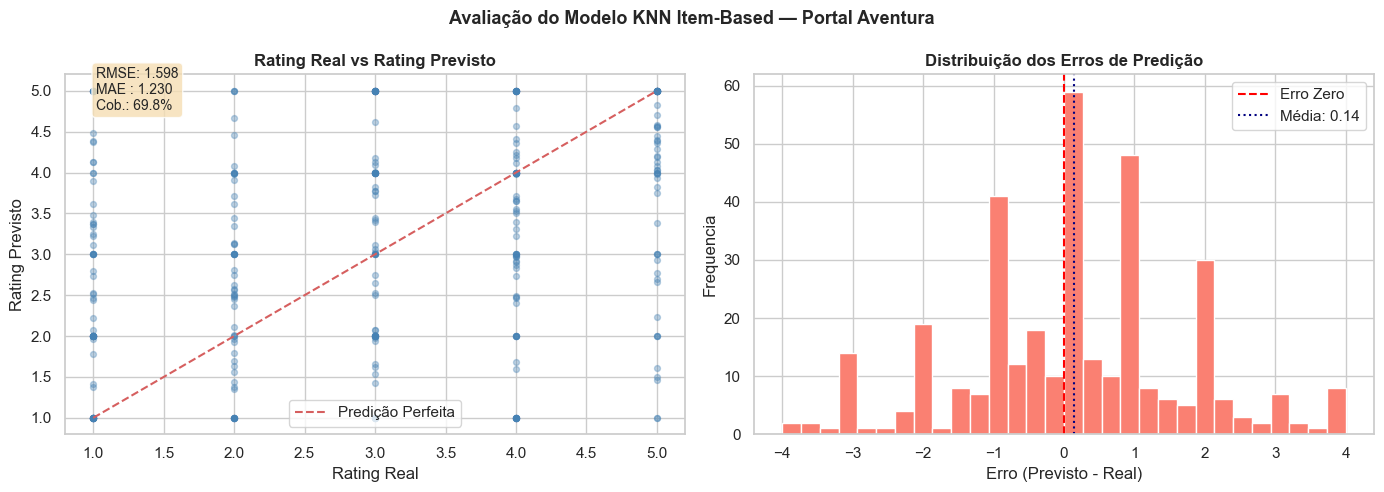

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Avaliação do Modelo KNN Item-Based — Portal Aventura',
             fontsize=13, fontweight='bold')

# Scatter: real vs previsto
axes[0].scatter(y_real, y_previsto, alpha=0.35, color='steelblue', s=18)
lims = [min(min(y_real), min(y_previsto)), max(max(y_real), max(y_previsto))]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Predição Perfeita')
axes[0].set_xlabel('Rating Real')
axes[0].set_ylabel('Rating Previsto')
axes[0].set_title('Rating Real vs Rating Previsto', fontweight='bold')
axes[0].legend()
axes[0].text(0.05, 0.90,
             f'RMSE: {rmse:.3f}\nMAE : {mae:.3f}\nCob.: {cobertura:.1f}%',
             transform=axes[0].transAxes,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
             fontsize=10)

# Histograma de erros
erros = np.array(y_previsto) - np.array(y_real)
axes[1].hist(erros, bins=30, color='salmon', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Erro Zero')
axes[1].axvline(erros.mean(), color='navy', linestyle=':', linewidth=1.5,
                label=f'Média: {erros.mean():.2f}')
axes[1].set_xlabel('Erro (Previsto - Real)')
axes[1].set_ylabel('Frequencia')
axes[1].set_title('Distribuição dos Erros de Predição', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(IMG_DIR / 'avaliacao_knn.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 10. Preparacao para Comparacao com SVD

Para facilitar a comparação futura com SVD Clássico e Funk SVD, estruturamos uma tabela comparativa padronizada que será preenchida com os resultados dos modelos subsequentes.

### Diferencas conceituais: KNN vs SVD

| Aspecto | KNN Item-Based | SVD Clássico | Funk SVD |
|---|---|---|---|
| Tipo | Memoria (lazy learning) | Modelo (fatorizacao) | Modelo (fatorizacao) |
| Treinamento | Indexacao da matriz | Decomposicao SVD completa | SGD iterativo |
| Predicao | Busca por vizinhos | Produto de vetores latentes | Produto de vetores latentes |
| Esparsidade | Sensivel — cobertura limitada | Lida bem — fatoriza a matriz densa | Lida bem — opera diretamente nos pares observados |
| Escalabilidade | O(n²) na predição | O(k) na predição após treino | O(k) na predição após treino |
| Interpretabilidade | Alta — vizinhos sao espetaculos reais | Baixa — fatores latentes sem significado direto | Baixa — fatores latentes sem significado direto |
| Hiperparametros | k, métrica | n_fatores | n_fatores, learning_rate, regularizacao |

O SVD resolve a principal limitacao do KNN neste contexto: a esparsidade de 98,62% da matriz reduz a cobertura das predicoes do metodo baseado em memoria. Modelos de fatorizacao matricial operam sobre os padrões latentes dos dados e podem gerar predicoes mesmo em regioes esparsas.

In [68]:
# Tabela comparativa: KNN preenchido; SVD fica para etapa posterior
resultados_comparativos = [
    {
        'Modelo'          : 'KNN Item-Based',
        'Tipo'            : 'Memoria',
        'RMSE'            : round(rmse, 4),
        'MAE'             : round(mae, 4),
        'Cobertura (%)'   : round(cobertura, 1),
        'Hit Rate@10 (%)' : round(hit_rate_10, 1),
        'Hiperparâmetros' : f'k={N_VIZINHOS}, métrica=cosseno'
    },
    {
        'Modelo'          : 'SVD Clássico',
        'Tipo'            : 'Fatorização Matricial',
        'RMSE'            : '-',
        'MAE'             : '-',
        'Cobertura (%)'   : '-',
        'Hit Rate@10 (%)' : '-',
        'Hiperparâmetros' : 'n_fatores=?'
    },
    {
        'Modelo'          : 'Funk SVD',
        'Tipo'            : 'Fatorização Matricial',
        'RMSE'            : '-',
        'MAE'             : '-',
        'Cobertura (%)'   : '-',
        'Hit Rate@10 (%)' : '-',
        'Hiperparâmetros' : 'n_fatores=?, lr=?, reg=?'
    }
]

df_comparativo = pd.DataFrame(resultados_comparativos)

display(df_comparativo.set_index('Modelo'))

# Salvar para uso em comparações futuras
df_comparativo.to_csv('../dataset/comparativo_modelos.csv', index=False, encoding='utf-8-sig')


,Tipo,RMSE,MAE,Cobertura (%),Hit Rate@10 (%),Hiperparâmetros
Modelo,,,,,,
KNN Item-Based,Memoria,1.5977,1.2296,69.8,26.2,"k=20, métrica=cosseno"
SVD Clássico,Fatorização Matricial,-,-,-,-,n_fatores=?
Funk SVD,Fatorização Matricial,-,-,-,-,"n_fatores=?, lr=?, reg=?"


---
## 11. Exportação do Modelo

Os artefatos necessários para reprodução do sistema de recomendação e futura integração com o Portal Aventura foram serializados utilizando `joblib`, biblioteca mais eficiente para armazenamento de objetos NumPy, SciPy e modelos do Scikit-Learn com estruturas matriciais de maior dimensão.

As imagens `eda_modelagem.png`, `mapa_similaridade_knn.png` e `avaliacao_knn.png` são exportadas para `documentos/img`, pois compõem as evidências visuais utilizadas na documentação técnica do projeto. Já o arquivo `comparativo_modelos.csv` é salvo em `dataset`, mantendo os dados analíticos e resultados experimentais centralizados junto ao conjunto de dados tratado.

In [69]:
MODELOS_DIR = os.path.normpath('../modelos')
os.makedirs(MODELOS_DIR, exist_ok=True)

modelos_por_k = {}
for k in K_COMPARACAO:
    modelo_k = NearestNeighbors(
        n_neighbors=k,
        metric=METRICA,
        algorithm=ALGORITMO,
        n_jobs=-1
    )
    modelo_k.fit(matriz_esparsa)
    modelos_por_k[k] = modelo_k

    modelo_k_path = os.path.join(MODELOS_DIR, f'modelo_knn_k{k}.pkl')
    joblib.dump(modelo_k, modelo_k_path)
    print(f'Modelo KNN k={k:<2} salvo       -> {modelo_k_path}')

modelo_path = os.path.join(MODELOS_DIR, 'modelo_knn.pkl')
joblib.dump(modelos_por_k[N_VIZINHOS], modelo_path)
print(f'Modelo KNN final salvo      -> {modelo_path}')

matriz_item_usuario_path = os.path.join(MODELOS_DIR, 'matriz_item_usuario.pkl')
joblib.dump(matriz_item_usuario, matriz_item_usuario_path)
print(f'Matriz pivot salva          -> {matriz_item_usuario_path}')

matriz_esparsa_path = os.path.join(MODELOS_DIR, 'matriz_esparsa.pkl')
joblib.dump(matriz_esparsa, matriz_esparsa_path)
print(f'Matriz esparsa salva        -> {matriz_esparsa_path}')

mapeamentos = {
    'item_to_idx': item_to_idx,
    'idx_to_item': idx_to_item,
    'item_ids': item_ids,
    'modelo_final_k': N_VIZINHOS,
    'modelos_comparados': K_COMPARACAO
}

mapeamentos_path = os.path.join(MODELOS_DIR, 'mapeamentos_itens.pkl')
joblib.dump(mapeamentos, mapeamentos_path)
print(f'Mapeamentos salvos          -> {mapeamentos_path}')

print('\nArquivos gerados:')
for f in sorted(os.listdir(MODELOS_DIR)):
    caminho = os.path.join(MODELOS_DIR, f)
    tamanho = os.path.getsize(caminho) / 1024
    print(f'   {f:25s} {tamanho:10.2f} KB')


Modelo KNN k=15 salvo       -> ..\modelos\modelo_knn_k15.pkl
Modelo KNN k=20 salvo       -> ..\modelos\modelo_knn_k20.pkl
Modelo KNN final salvo      -> ..\modelos\modelo_knn.pkl
Matriz pivot salva          -> ..\modelos\matriz_item_usuario.pkl
Matriz esparsa salva        -> ..\modelos\matriz_esparsa.pkl
Mapeamentos salvos          -> ..\modelos\mapeamentos_itens.pkl

Arquivos gerados:
   mapeamentos_itens.pkl           3.89 KB
   matriz_esparsa.pkl            480.49 KB
   matriz_item_usuario.pkl     23244.92 KB
   modelo_knn.pkl                480.83 KB
   modelo_knn_k15.pkl            480.83 KB
   modelo_knn_k20.pkl            480.83 KB


In [70]:
warnings.filterwarnings(
    'ignore',
    message='`sklearn.utils.parallel.delayed`',
    category=UserWarning,
    module='sklearn.utils.parallel'
)

# Verificação de carregamento em outro contexto

print('Testando carregamento dos modelos salvos...')

modelo_carregado = joblib.load(modelo_path)
modelo_k15_load  = joblib.load(os.path.join(MODELOS_DIR, 'modelo_knn_k15.pkl'))
modelo_k20_load  = joblib.load(os.path.join(MODELOS_DIR, 'modelo_knn_k20.pkl'))
mapeamentos_load = joblib.load(mapeamentos_path)
matriz_load      = joblib.load(matriz_esparsa_path)

# Teste funcional: buscar vizinhos do primeiro item do catálogo
item_teste  = mapeamentos_load['item_ids'][0]
idx_teste   = mapeamentos_load['item_to_idx'][item_teste]
dists, idxs = modelo_carregado.kneighbors(matriz_load[idx_teste], n_neighbors=3)

print('Modelos carregados e validados com sucesso')
print(f'   Modelo final       : k={modelo_carregado.n_neighbors}')
print(f'   Modelo comparativo : k={modelo_k15_load.n_neighbors}')
print(f'   Modelo comparativo : k={modelo_k20_load.n_neighbors}')
print(f'   Item de teste      : ID {item_teste}')
print(f'   Vizinhos           : {idxs.flatten().tolist()}')
print(f'   Distâncias         : {[round(d, 4) for d in dists.flatten().tolist()]}')

Testando carregamento dos modelos salvos...
Modelos carregados e validados com sucesso
   Modelo final       : k=20
   Modelo comparativo : k=15
   Modelo comparativo : k=20
   Item de teste      : ID 0
   Vizinhos           : [0, 257, 23]
   Distâncias         : [0.0, 0.8815, 0.9217]


---
## 12. Conclusão

### Síntese da Entrega

O notebook implementa um modelo de filtragem colaborativa baseada em itens com KNN para o Portal Aventura. A solução usa o dataset balanceado da Sprint 1, constrói uma matriz item-usuário, treina o `NearestNeighbors` com distância cosseno, disponibiliza uma função de inferência funcional e exporta os artefatos necessários para reuso do modelo.

A checagem exploratória desta etapa foi mantida de forma objetiva porque a exploração detalhada e o tratamento dos dados já foram realizados em `tratamento-dados.ipynb`. Aqui, a análise se concentra nos aspectos que impactam diretamente o KNN: volume de usuários e itens, distribuição dos ratings, densidade da matriz e quantidade de interações por usuário e espetáculo.

### Comparação dos valores de k

O hiperparâmetro `k` define quantos vizinhos o KNN considera ao estimar similaridade e gerar predições. Foram comparados `k=15` e `k=20` usando o mesmo split treino/teste e a mesma amostra de 500 registros do conjunto de teste. O objetivo foi verificar se uma vizinhança maior aumentaria a cobertura sem piorar as métricas de erro.

| k | RMSE | MAE | Cobertura | Predições válidas |
|---|---:|---:|---:|---:|
| 15 | 1,6353 | 1,2621 | 64,0% | 320 |
| 20 | 1,5977 | 1,2296 | 69,8% | 349 |

O `k=20` foi mantido como configuração final porque teve menor RMSE, menor MAE e maior cobertura. Em uma matriz com 98,6229% de esparsidade, a cobertura é especialmente importante: quanto maior o número de pares usuário-item com vizinhos suficientes, menor a quantidade de casos em que o modelo não consegue gerar estimativa.

### Onde estão os modelos k=15 e k=20

Ao executar o notebook, os dois modelos comparados s?o gerados localmente em `src/modelos`:

| Arquivo | Configuração | Uso |
|---|---|---|
| `modelo_knn_k15.pkl` | KNN item-based com `k=15` | Artefato de comparação do hiperparâmetro |
| `modelo_knn_k20.pkl` | KNN item-based com `k=20` | Artefato escolhido como modelo final |
| `modelo_knn.pkl` | Alias do `modelo_knn_k20.pkl` | Caminho padrão para inferência |

Tecnicamente, os dois modelos usam a mesma matriz item-usuário e a mesma métrica cosseno; o que muda é o número de vizinhos armazenado no objeto `NearestNeighbors`. Por isso, a comparação é feita mantendo o restante do pipeline constante e alterando apenas o `k`.

### Leitura dos Resultados

A matriz final apresentou 40.848 interações, 8.648 usuários, 343 espetáculos e esparsidade de 98,6229%. Esse nível de esparsidade é esperado em sistemas de recomendação, mas é o principal fator limitante do KNN: quando o usuário não possui avaliações em comum com itens vizinhos, o modelo não consegue estimar o rating.

Na avaliação com split 80/20 e amostra de 500 registros do conjunto de teste, o modelo final (`k=20`) obteve RMSE de 1,5977, MAE de 1,2296 e cobertura de 69,8% (349 predições válidas em 500 casos avaliados). O MAE indica que, quando há predição, o erro médio é de aproximadamente 1,23 ponto na escala de 1 a 5. A cobertura mostra que cerca de 30% dos pares avaliados não teve vizinhança suficiente para gerar estimativa, reforçando a esparsidade como a maior fragilidade operacional do KNN.

Como métrica de ranking, o modelo alcançou Hit Rate@10 de 26,2% (123 acertos em 469 usuários avaliáveis). Isso significa que, em cerca de um quarto dos casos avaliáveis, ao menos um item retido no teste apareceu entre as 10 recomendações geradas a partir do histórico de treino do usuário. O resultado é compatível com um baseline colaborativo interpretável, mas ainda indica espaço para modelos mais robustos à esparsidade.

### Dataset e Resultados

| Métrica | Valor |
|---|---|
| Registros brutos originais | 343.758 |
| Registros após tratamento Sprint 1 | 40.848 |
| Usuários no dataset final | 8.648 |
| Espetáculos no dataset final | 343 |
| Esparsidade da matriz | 98,6229% |
| Vizinhos comparados | k=15 e k=20 |
| Modelo final selecionado | k=20 |
| Métrica de similaridade | Cosseno |
| Split treino/teste | 80% / 20% |
| Amostra de avaliação | 500 registros do teste |
| RMSE (teste, k=20) | 1,5977 |
| MAE (teste, k=20) | 1,2296 |
| Cobertura (k=20) | 69,8% |
| Hit Rate@10 | 26,2% |

---

### Próximos Passos

1. **Avaliar o conjunto de teste completo**: remover a amostragem de 500 registros quando houver tempo computacional suficiente;
2. **Ampliar métricas de ranking**: complementar Hit Rate@10 com Precision@K, Recall@K e NDCG@K;
3. **Comparar com SVD e Funk SVD**: verificar se modelos de fatorização aumentam a cobertura em uma matriz muito esparsa;
4. **Integrar metadados dos espetáculos**: combinar filtragem colaborativa com categoria, teatro e outras informações de conteúdo para reduzir problemas de cold start;
5. **Integrar ao portal**: quando necessário, gerar os artefatos em `src/modelos` e consumi-los em uma API ou serviço de recomendação.
